# **Supporting Information: figures and tables**

This notebook makes the figures and tables of the Supporting Information.

This notebook uses the outputs of `gic_psp_corrosion_workflow.ipynb`: it does not compute the geoelectric field or the pipeline model again, but reads the CSV files that the main notebook saves in `outputs/processed` (geoelectric field, field parallel to the pipeline, circuit parameters and PSP). If these files are not found, the Setup runs the main notebook first (about 1 minute). The figures are saved in `outputs/figures` and the tables in `outputs/tables_si`.

## **Setup**

Imports, folders and the settings shared by all sections. The values are the same as in the main notebook.

In [1]:
# Clone the repository only when the data folders are not in the current folder (e.g. on Google Colab)
import os

if not os.path.exists("data-magnetometer_MAN"):
    if not os.path.exists("gic-urucu-manaus-pipeline"):
        os.system("git clone https://github.com/LopesMAM/gic-urucu-manaus-pipeline.git")
    os.chdir("gic-urucu-manaus-pipeline")

In [2]:
# Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

In [3]:
# Folders: the CSV files of the main notebook are read from output_folder
magnetometer_folder = "data-magnetometer_MAN"
output_folder = "outputs/processed"
figures_folder = "outputs/figures"
tables_folder = "outputs/tables_si"
pipeline_circuit_path = output_folder + "/pipeline_circuit_parameters.csv"

if not os.path.exists(pipeline_circuit_path):
    print("Outputs of the main notebook not found: running gic_psp_corrosion_workflow.ipynb first (about 1 minute)...")
    os.system("jupyter nbconvert --to notebook --execute gic_psp_corrosion_workflow.ipynb --output gic_psp_corrosion_workflow_executed.ipynb")

os.makedirs(figures_folder, exist_ok=True)
os.makedirs(tables_folder, exist_ok=True)

In [4]:
# Settings (same values as in the main notebook)
events = [
    {"id": 1, "name": "21-23 Apr. 2017", "period": "April",
     "exposure_start": pd.Timestamp("2017-04-21 10:52"), "exposure_end": pd.Timestamp("2017-04-23 23:59")},
    {"id": 2, "name": "16-17 Jul. 2017", "period": "July",
     "exposure_start": pd.Timestamp("2017-07-16 00:00"), "exposure_end": pd.Timestamp("2017-07-17 19:12")},
]

zt_values = [0.1, 1, 10, 100]
base_psp_V = -1.025
threshold_V = -0.85
minutes_per_year = 365 * 24 * 60

# coating conductance used in the main text (S/m2)
coating_conductance_garsol = 1e-6
coating_conductance_gascom = 1e-8

threshold_mV = threshold_V * 1000
baseline_mV = base_psp_V * 1000

font_props = {"family": "serif"}
plt.rcParams["font.family"] = "serif"
plt.rcParams["mathtext.fontset"] = "dejavuserif"

In [5]:
# Pipeline model saved by the main notebook: distance of each node, section of each node and circuit of each segment
df_circuit = pd.read_csv(pipeline_circuit_path)
n_nodes = len(df_circuit)
n_segments = n_nodes - 1

distance_km = np.zeros(n_nodes)
for i in range(1, n_nodes):
    distance_km[i] = distance_km[i - 1] + df_circuit["prev_dist"].iloc[i]

# km of the basin boundary and of the GARSOL/GASCOM boundary
for i in range(1, n_nodes):
    if df_circuit["Basin"].iloc[i] != df_circuit["Basin"].iloc[i - 1]:
        basin_line_km = distance_km[i]
    if df_circuit["Pipeline"].iloc[i] != df_circuit["Pipeline"].iloc[i - 1]:
        pipeline_line_km = distance_km[i]

# nodes of each section
garsol_nodes = []
gascom_nodes = []
for i in range(n_nodes):
    if "GARSOL" in df_circuit["Pipeline"].iloc[i]:
        garsol_nodes.append(i)
    else:
        gascom_nodes.append(i)

# pipeline length represented by each node: half of the segment on each side
node_length_km = np.zeros(n_nodes)
for i in range(n_segments):
    segment_km = distance_km[i + 1] - distance_km[i]
    node_length_km[i] = node_length_km[i] + segment_km / 2
    node_length_km[i + 1] = node_length_km[i + 1] + segment_km / 2

# circuit of each segment (segment i goes from node i to node i+1)
Ye_all = df_circuit["Ye (S)"].values[:-1]
Ysh_all = df_circuit["Ysh (S)"].values[:-1]
Z_all = df_circuit["Z (ohm/km)"].values[:-1]
Y_all = df_circuit["Y (S/km)"].values[:-1]
segment_km_all = df_circuit["prev_dist"].values[1:]

## **Functions used in several sections**

`solve_psp` gives the PSP of every node and minute for one terminating impedance, with the same DSTL equations as the main notebook. `corrosion_per_node` gives the corrosion contribution and the exposure time of each node, with the same exposure intervals, mean overpotential and Birbilis correction as the main notebook.

In [6]:
def solve_psp(e_parallel, Ye, Ysh, Z, zt, base_V):
    # e_parallel: field along each segment (V/km), shape (segments, minutes)
    n = len(Ye) + 1

    # nodal admittance matrix
    Y = np.zeros((n, n))
    for i in range(n - 1):
        Y[i, i] = Y[i, i] + Ysh[i] + Ye[i]
    for i in range(n - 1):
        Y[i + 1, i + 1] = Y[i + 1, i + 1] + Ysh[i] + Ye[i]
    for i in range(n - 1):
        Y[i, i + 1] = -Ye[i]
        Y[i + 1, i] = -Ye[i]
    Y[0, 0] = Y[0, 0] + 1 / zt
    Y[n - 1, n - 1] = Y[n - 1, n - 1] + 1 / zt

    # nodal currents: each segment source Ie = E/Z leaves its start node and enters its end node
    J = np.zeros((n, e_parallel.shape[1]))
    for i in range(n - 1):
        Ie = e_parallel[i] / Z[i]
        J[i] = J[i] - Ie
        J[i + 1] = J[i + 1] + Ie

    V = np.linalg.solve(Y, J)
    return base_V + V


def corrosion_per_node(psp):
    # psp: PSP (V) of each node and minute; returns the corrosion contribution (mm/yr) and exposure time (min) of each node
    n_nodes_psp = psp.shape[0]
    n_minutes = psp.shape[1]
    cr = np.zeros(n_nodes_psp)
    exposure = np.zeros(n_nodes_psp)

    for node in range(n_nodes_psp):
        values = psp[node].tolist()
        duration = 0
        excess_sum = 0.0
        for minute in range(n_minutes):
            if values[minute] > threshold_V:
                duration = duration + 1
                excess_sum = excess_sum + (values[minute] - threshold_V)

            # the interval closes at the last minute or when the next minute is not exposed
            if duration == 0:
                interval_ends = False
            elif minute == n_minutes - 1:
                interval_ends = True
            else:
                interval_ends = not (values[minute + 1] > threshold_V)

            if interval_ends:
                mean_vi = excess_sum / duration

                # Birbilis correction for clay soil (intervals shorter than 12 h)
                duration_s = duration * 60
                if duration_s < 12 * 3600:
                    rcr = 6e-6 * duration_s ** 1.1
                else:
                    rcr = 1.0

                interval_cr = 25.36 * rcr * mean_vi * (duration / minutes_per_year)
                cr[node] = cr[node] + interval_cr
                exposure[node] = exposure[node] + duration
                duration = 0
                excess_sum = 0.0

    return cr, exposure


def read_psp(event, zt):
    # PSP (V) saved by the main notebook, only the minutes of the exposure window
    df_psp = pd.read_csv(output_folder + "/psp_results/event_" + str(event["id"]) + "/psp_zt_" + str(zt) + ".csv")
    times = pd.to_datetime(df_psp.columns[1:])
    in_window = (times >= event["exposure_start"]) & (times <= event["exposure_end"])
    psp = df_psp.iloc[:, 1:].values[:, in_window]
    times_window = times[in_window]
    return psp, times_window


def sci(x):
    # number in scientific notation for the tables, e.g. 1.27 x 10^-4
    if x == 0 or np.isnan(x):
        return "-"
    return "{:.2e}".format(x)

# **Text S2: Sensitivity to the 1D resistivity model (Tables S4 to S8)**

The calculations are repeated with a single 1D resistivity model along the whole pipeline. The main notebook already saves the geoelectric field of both models for the whole period, so the Solimões-only configuration uses the Solimões field on every segment and the Amazonas-only configuration uses the Amazonas field on every segment. The Two-basin configuration is the one of the main text.

In [7]:
# azimuth of each segment and basin of its start point
azimuth_rad = np.deg2rad(df_circuit["Azimuth (°)"].values[:-1])
segment_in_solimoes = []
for i in range(n_segments):
    segment_in_solimoes.append("Solimões" in df_circuit["Basin"].iloc[i])

configurations = ["Two-basin", "Solimões-only", "Amazonas-only"]
rows_s4 = []
rows_s5 = []
rows_s6 = []
rows_s7 = []
rows_s8 = []

for event in events:
    df_field = pd.read_csv(output_folder + "/electric_field_event_" + str(event["id"]) + ".csv")
    df_field["datetime"] = pd.to_datetime(df_field["datetime"])
    in_window = (df_field["datetime"] >= event["exposure_start"]) & (df_field["datetime"] <= event["exposure_end"])
    df_field = df_field[in_window]

    results = {}
    for config in configurations:
        # basin used on each segment
        basin_of_segment = []
        for i in range(n_segments):
            if config == "Solimões-only":
                basin_of_segment.append("solimoes")
            elif config == "Amazonas-only":
                basin_of_segment.append("amazonas")
            elif segment_in_solimoes[i]:              # Two-basin: basin of the segment start point
                basin_of_segment.append("solimoes")
            else:
                basin_of_segment.append("amazonas")

        # field parallel to each segment (V/km)
        e_parallel = np.zeros((n_segments, len(df_field)))
        for i in range(n_segments):
            ex = df_field["Ex_" + basin_of_segment[i] + "_Vkm"].values
            ey = df_field["Ey_" + basin_of_segment[i] + "_Vkm"].values
            e_parallel[i] = ex * np.cos(azimuth_rad[i]) + ey * np.sin(azimuth_rad[i])

        # basins used in this configuration (each one once)
        basins_used = []
        for basin in basin_of_segment:
            if basin not in basins_used:
                basins_used.append(basin)

        # maximum surface field of the basins used (mV/km)
        max_field = {}
        for component in ["Ex", "Ey", "E"]:
            values = []
            for basin in basins_used:
                field = df_field[component + "_" + basin + "_Vkm"].values
                max_abs = np.nanmax(np.abs(field))
                values.append(max_abs * 1000)
            max_field[component] = max(values)

        # maximum field parallel to the pipeline (mV/km)
        max_e_parallel = np.nanmax(np.abs(e_parallel)) * 1000

        # PSP, corrosion and exposure for each Zt
        per_zt = {}
        for zt in zt_values:
            psp = solve_psp(e_parallel, Ye_all, Ysh_all, Z_all, zt, base_psp_V)
            cr, exposure = corrosion_per_node(psp)

            # maximum PSP in each section (mV)
            psp_garsol = np.nanmax(psp[garsol_nodes]) * 1000
            psp_gascom = np.nanmax(psp[gascom_nodes]) * 1000

            per_zt[zt] = {"cr": cr, "exposure": exposure, "psp_garsol": psp_garsol, "psp_gascom": psp_gascom}

        results[config] = {"field": max_field, "e_parallel": max_e_parallel, "zt": per_zt}

    # Table S4: one row per period and field component
    component_names = {"Ex": "Ex (north)", "Ey": "Ey (east)", "E": "|E|"}
    for component in component_names:
        row = {"Period": event["period"], "Component": component_names[component]}
        for config in configurations:
            row[config + " (mV/km)"] = round(results[config]["field"][component], 2)
        rows_s4.append(row)

    # Table S5: one row per period
    row = {"Period": event["period"]}
    for config in configurations:
        row[config + " (mV/km)"] = round(results[config]["e_parallel"], 2)
    rows_s5.append(row)

    # Tables S6, S7 and S8: one row per period and Zt
    for zt in zt_values:
        row6 = {"Period": event["period"], "Zt (ohm)": zt}
        row7 = {"Period": event["period"], "Zt (ohm)": zt}
        row8 = {"Period": event["period"], "Zt (ohm)": zt}
        for config in configurations:
            cr = results[config]["zt"][zt]["cr"]
            exposure = results[config]["zt"][zt]["exposure"]

            # number of nodes with some exposure
            n_exposed = 0
            for node in range(len(exposure)):
                if exposure[node] > 0:
                    n_exposed = n_exposed + 1

            row6[config + " (mm/yr)"] = sci(cr.max())
            row7[config] = n_exposed
            row8["GARSOL " + config + " (mV)"] = round(results[config]["zt"][zt]["psp_garsol"], 1)
            row8["GASCOM " + config + " (mV)"] = round(results[config]["zt"][zt]["psp_gascom"], 1)

        # location of the largest corrosion in the Two-basin configuration
        node_max_cr = np.argmax(results["Two-basin"]["zt"][zt]["cr"])
        row6["Distance along the pipeline (km)"] = round(distance_km[node_max_cr])

        rows_s6.append(row6)
        rows_s7.append(row7)
        rows_s8.append(row8)

tables = {
    "S4": pd.DataFrame(rows_s4),
    "S5": pd.DataFrame(rows_s5),
    "S6": pd.DataFrame(rows_s6),
    "S7": pd.DataFrame(rows_s7),
    "S8": pd.DataFrame(rows_s8),
}

for name in tables:
    tables[name].to_csv(tables_folder + "/Table_" + name + ".csv", index=False)
    print("Table " + name)
    print(tables[name].to_string(index=False))
    print()

Table S4
Period  Component  Two-basin (mV/km)  Solimões-only (mV/km)  Amazonas-only (mV/km)
 April Ex (north)               2.50                   2.50                   2.49
 April  Ey (east)              11.99                  11.94                  11.99
 April        |E|              12.25                  12.20                  12.25
  July Ex (north)               6.35                   6.35                   6.25
  July  Ey (east)              22.79                  22.71                  22.79
  July        |E|              22.80                  22.72                  22.80

Table S5
Period  Two-basin (mV/km)  Solimões-only (mV/km)  Amazonas-only (mV/km)
 April              12.24                  12.20                  12.25
  July              22.80                  22.72                  22.80

Table S6
Period  Zt (ohm) Two-basin (mm/yr) Solimões-only (mm/yr) Amazonas-only (mm/yr)  Distance along the pipeline (km)
 April       0.1          1.79e-09              2.56e-09     

# **Text S3: Modeled PSP time series (Figure S1)**

dH/dt at MAN (top row) and PSP time series for each terminating impedance Zt (other rows), for each event (columns). The PSP is shown at three locations: Urucu (blue), the GARSOL/GASCOM boundary (gray) and Manaus (orange). The gray horizontal line marks the -1025 mV cathodic protection baseline (zero in the top row), the dotted line the -850 mV protection threshold, and the vertical dashed lines midnight UT.

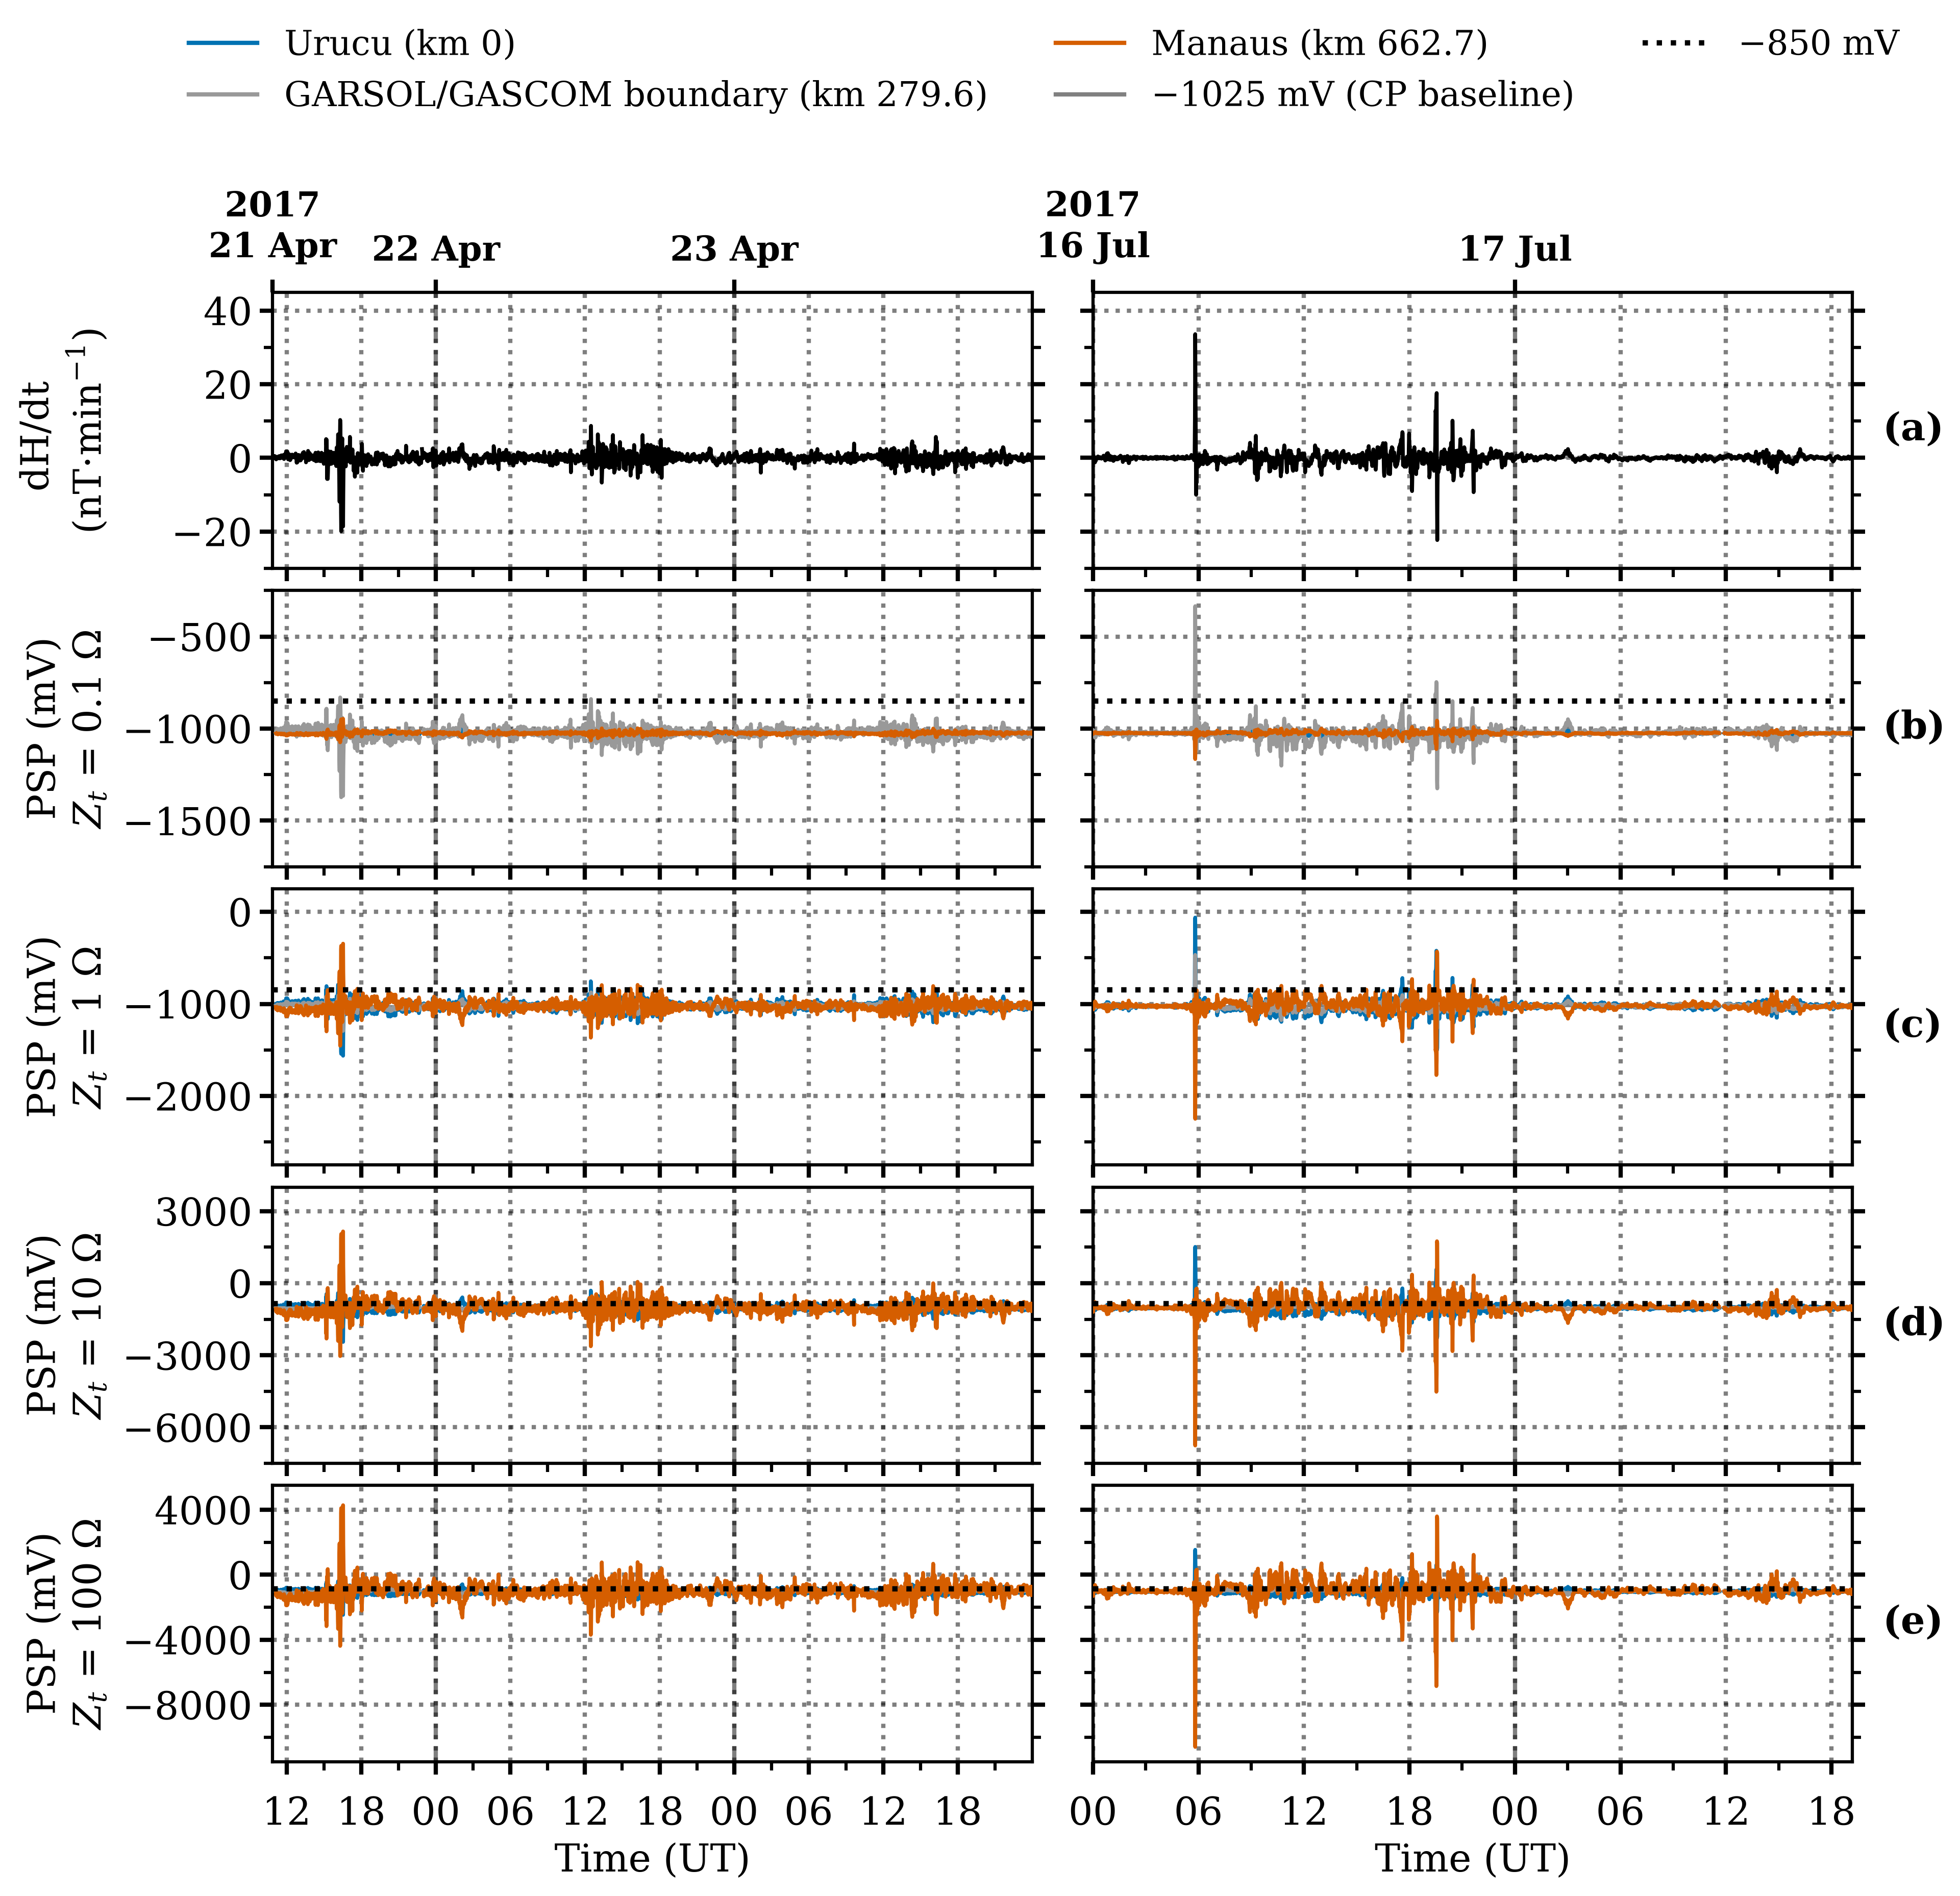

In [8]:
# dH/dt at MAN and PSP time series at three pipeline locations, for each terminating impedance
boundary_km = pipeline_line_km

# node closest to the GARSOL/GASCOM boundary
boundary_node = int(np.argmin(np.abs(distance_km - boundary_km)))

location_names = [
    "Urucu (km 0)",
    "GARSOL/GASCOM boundary (km " + str(round(boundary_km, 1)) + ")",
    "Manaus (km " + str(round(distance_km[-1], 1)) + ")",
]
location_nodes = [0, boundary_node, n_nodes - 1]
location_colors = ["#0072B2", "#999999", "#D55E00"]

# H at MAN (1-min), from all magnetometer files
times_H = []
values_H = []
for file_name in sorted(os.listdir(magnetometer_folder)):
    with open(magnetometer_folder + "/" + file_name) as f:
        lines = f.readlines()
    for line in lines[3:]:
        parts = line.split()
        if len(parts) < 7:
            continue
        times_H.append(pd.Timestamp(year=int(parts[2]), month=int(parts[1]), day=int(parts[0]), hour=int(parts[3]), minute=int(parts[4])))
        values_H.append(float(parts[6]))

df_H = pd.DataFrame({"t": times_H, "H": values_H})
df_H = df_H.drop_duplicates("t")
H = df_H.set_index("t")["H"].sort_index()

# Data of each event: times of the window, dH/dt (nT/min) and PSP (mV) for each Zt
times_by_event = {}
dh_by_event = {}
psp_by_event = {}

for event in events:
    event_id = event["id"]
    psp_by_event[event_id] = {}

    for zt in zt_values:
        df = pd.read_csv(output_folder + "/psp_results/event_" + str(event_id) + "/psp_zt_" + str(zt) + ".csv")
        times = pd.to_datetime(df.columns[1:])
        in_window = (times >= event["exposure_start"]) & (times <= event["exposure_end"])
        psp_by_event[event_id][zt] = 1000 * df.iloc[:, 1:].values[:, in_window]

    times_window = pd.DatetimeIndex(times[in_window])
    times_by_event[event_id] = times_window

    # dH/dt = difference between consecutive minutes (NaN where a minute is missing)
    h_window = H.reindex(times_window)
    dh_by_event[event_id] = h_window.diff()

# Figure: first row dH/dt at MAN, then one row per terminating impedance; one color per location
nrows = 1 + len(zt_values)
n_events = len(events)
row_letters = ["a", "b", "c", "d", "e"]

ylabels = ["dH/dt \n(nT$\\cdot$min$^{-1}$)"]
for zt in zt_values:
    ylabels.append("PSP (mV)\n$Z_t$ = " + str(zt) + " $\\Omega$")

# Fixed limits and major tick step per row (both columns of a row share the same scale)
row_ylim = [(-30, 45), (-1750, -250), (-2750, 250), (-7500, 4000), (-11500, 5500)]
row_step = [20, 500, 1000, 3000, 4000]
fig, axes = plt.subplots(nrows=nrows, ncols=n_events, figsize=(6 * n_events, 12), sharex="col", sharey="row", squeeze=False, dpi=300)

for col in range(n_events):
    event_id = events[col]["id"]
    tt = times_by_event[event_id]
    dh = dh_by_event[event_id]
    psp = psp_by_event[event_id]

    plot_start = tt.min()
    plot_end = tt.max()
    hide_left_y = col > 0
    midnights = pd.date_range(start=plot_start.normalize(), end=plot_end.normalize() + pd.Timedelta(days=1), freq="D")

    for r in range(nrows):
        ax = axes[r, col]

        if r == 0:
            ax.plot(tt, dh, color="black", linewidth=1.8, zorder=5)
            ax.axhline(0, color="gray", linestyle="-", linewidth=1.0, zorder=2)
        else:
            zt = zt_values[r - 1]
            for i in range(len(location_nodes)):
                ax.plot(tt, psp[zt][location_nodes[i]], color=location_colors[i], linewidth=1.8, zorder=5)
            ax.axhline(baseline_mV, color="gray", linestyle="-", linewidth=1.0, zorder=2)
            ax.axhline(threshold_mV, color="black", linestyle=":", linewidth=2.5, zorder=6)

        ax.set_ylim(row_ylim[r])
        ax.yaxis.set_major_locator(MultipleLocator(row_step[r]))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.tick_params(axis="y", which="major", direction="out", length=6, width=2.0, colors="black", left=True, right=True, labelsize=18)
        ax.tick_params(axis="y", which="minor", direction="out", length=4, width=1.5, colors="black", left=True, right=True)
        if hide_left_y:
            ax.set_ylabel("")
            ax.tick_params(axis="y", labelleft=False, labelright=False)
        else:
            ax.set_ylabel(ylabels[r], fontsize=18, color="black", fontdict=font_props)
            for label in ax.get_yticklabels():
                label.set_fontproperties(font_props)
                label.set_fontsize(18)

        ax.grid(True, which="major", axis="both", color="black", alpha=0.5, linestyle=":", linewidth=2)

        # Letters (a)-(e) only in the last column, one per row, on the right side
        if col == n_events - 1:
            ax.text(1.04, 0.5, "(" + row_letters[r] + ")", transform=ax.transAxes, fontsize=18, fontweight="bold",
                    fontdict=font_props, va="center", ha="left", zorder=20, color="black")

        # Dashed vertical line at each midnight inside the window
        for mn in midnights:
            if plot_start <= mn <= plot_end:
                ax.axvline(mn, color="black", alpha=0.5, linestyle="--", linewidth=2.0, zorder=2)

        ax.set_axisbelow(True)
        ax.set_xlim(plot_start, plot_end)
        ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[3, 9, 15, 21]))
        for spine in ax.spines.values():
            spine.set_linewidth(1.5)
            spine.set_color("black")
        if r < nrows - 1:
            ax.tick_params(axis="x", which="major", direction="out", length=6, width=2.0, colors="black", labelbottom=False)
            ax.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5, colors="black", labelbottom=False)

    # Bottom x axis: hours
    ax_bottom = axes[-1, col]
    ax_bottom.set_xlabel("Time (UT)", fontsize=18, color="black", fontdict=font_props)
    ax_bottom.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
    ax_bottom.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
    ax_bottom.tick_params(axis="x", which="major", direction="out", length=6, width=2.0, pad=10, colors="black")
    ax_bottom.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5, colors="black")
    for label in ax_bottom.get_xticklabels():
        label.set_fontproperties(font_props)
        label.set_fontsize(18)

    # Top x axis: dates (first minute of each day; the year only on the first one)
    start_of_days = []
    for t in tt:
        if len(start_of_days) == 0 or t.date() != start_of_days[-1].date():
            start_of_days.append(t)

    tick_labels = []
    for i in range(len(start_of_days)):
        day = start_of_days[i]
        if i == 0:
            tick_labels.append(str(day.year) + "\n" + day.strftime("%d %b"))
        else:
            tick_labels.append(day.strftime("%d %b"))

    ax_top = axes[0, col].secondary_xaxis("top")
    ax_top.set_xticks(start_of_days)
    ax_top.set_xticklabels(tick_labels)
    ax_top.tick_params(axis="x", direction="out", length=6, width=2.0, pad=5, colors="black")
    for label in ax_top.get_xticklabels():
        label.set_fontproperties(font_props)
        label.set_fontsize(16)
        label.set_fontweight("bold")
        label.set_ha("center")

fig.align_ylabels(axes[:, 0])

# Global legend
legend_elements = []
for i in range(len(location_names)):
    legend_elements.append(Line2D([0], [0], color=location_colors[i], linewidth=2.0, label=location_names[i]))
legend_elements.append(Line2D([0], [0], color="gray", linestyle="-", linewidth=2.0, label=r"$-1025$ mV (CP baseline)"))
legend_elements.append(Line2D([0], [0], color="black", linestyle=":", linewidth=2.5, label=r"$-850$ mV"))
fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False, prop={"family": "serif", "size": 16})

plt.tight_layout(rect=[0, 0, 1, 1])
plt.subplots_adjust(hspace=0.08, wspace=0.08, top=0.86, bottom=0.06, left=0.08, right=0.94)

fig.savefig(figures_folder + "/FigS1_PSP_timeseries.png", dpi=300, bbox_inches="tight")
plt.show()

# **Text S4: Corrosion in the first 12 h of the April period (Figure S2)**

Corrosion contribution (red bars, left axis) and exposure time (blue line, right axis) along the pipeline for the full 21-23 April 2017 analysis window (left) and for its first 12 h only, from 10:52 to 22:51 UT on 21 April (right), for each terminating impedance Zt (rows). The orange line marks 0.025 mm·yr⁻¹, and the dash-dotted and dashed lines mark the basin and pipeline-section boundaries, respectively.

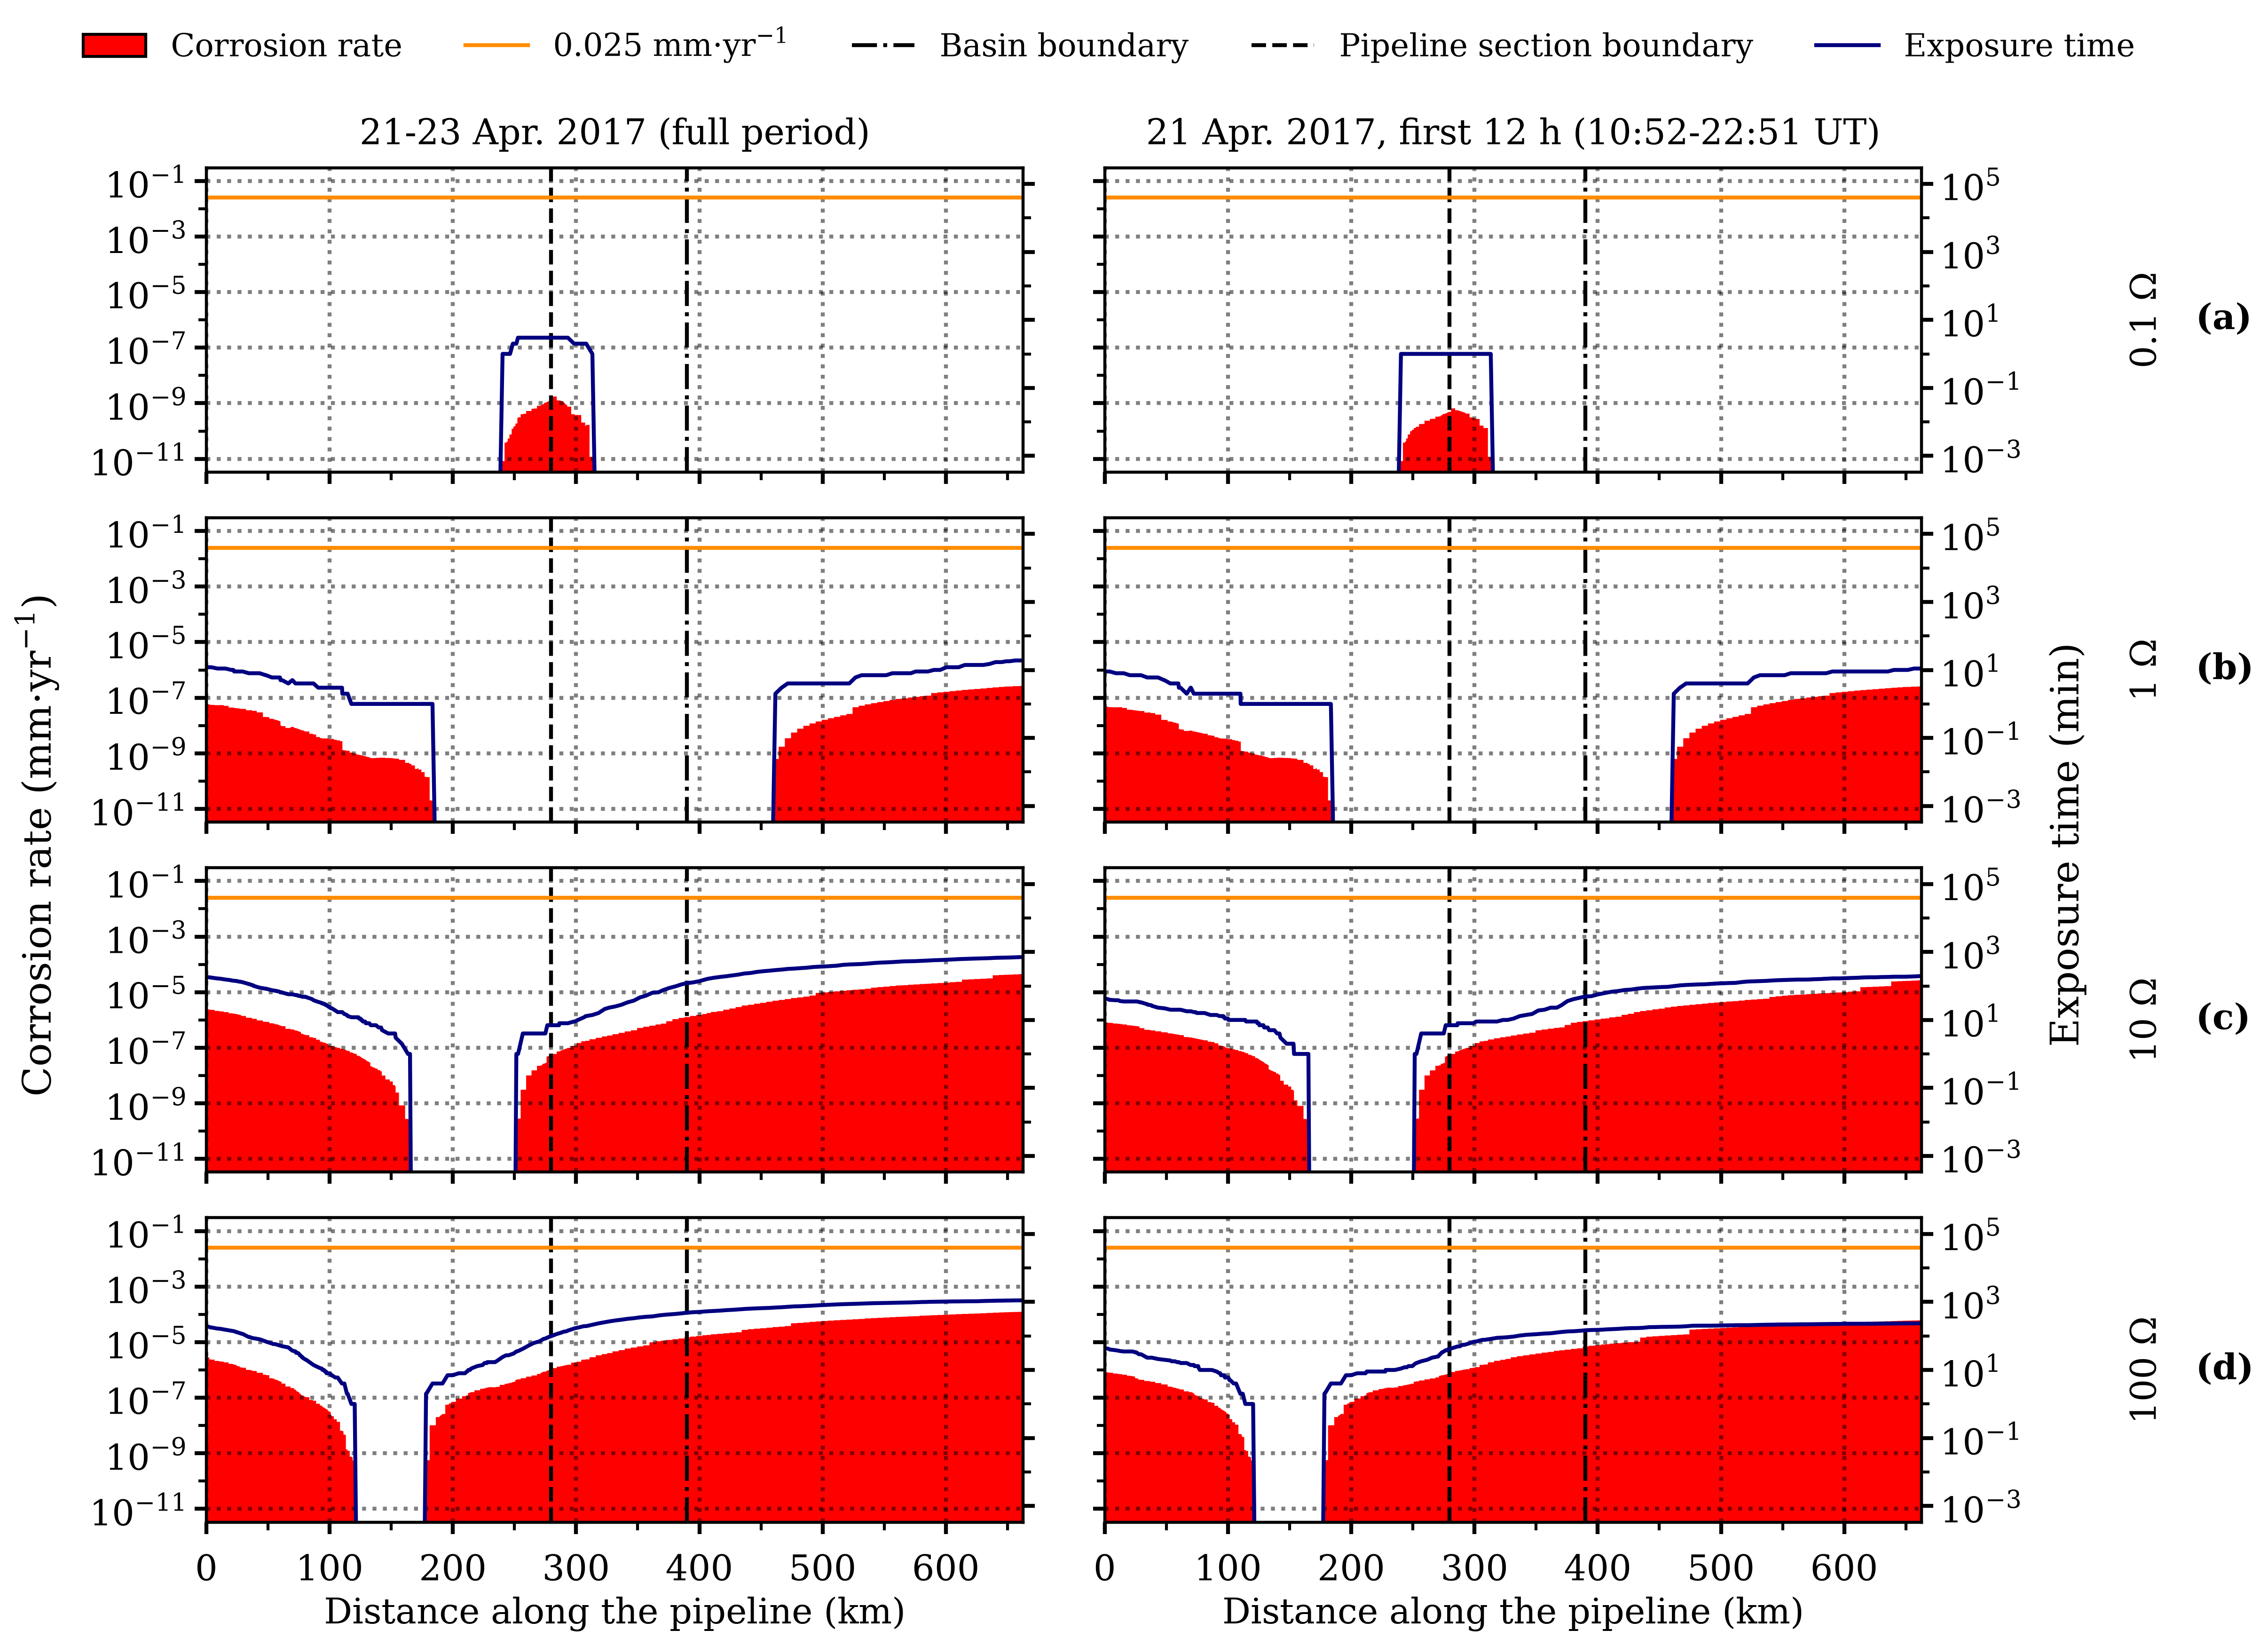

Zt = 0.1 | max full: 1.79e-09 | max first 12 h: 6.69e-10
Zt = 1 | max full: 2.70e-07 | max first 12 h: 2.58e-07
Zt = 10 | max full: 4.56e-05 | max first 12 h: 2.72e-05
Zt = 100 | max full: 1.27e-04 | max first 12 h: 6.24e-05


In [9]:
# corrosion and exposure of each node: full April window and its first 12 h (720 minutes)
april = events[0]
columns = [
    {"title": "21-23 Apr. 2017 (full period)", "minutes": None},
    {"title": "21 Apr. 2017, first 12 h (10:52-22:51 UT)", "minutes": 720},
]

for column in columns:
    column["cr"] = {}
    column["exposure"] = {}
    for zt in zt_values:
        psp, times = read_psp(april, zt)
        if column["minutes"] is not None:
            psp = psp[:, :column["minutes"]]
        cr, exposure = corrosion_per_node(psp)
        column["cr"][zt] = cr
        column["exposure"][zt] = exposure

# axis limits: corrosion from 10^-11 to 10^-1, exposure from 10^-3 to 10^5 minutes (with a visual margin)
pad_factor = 3.0
cr_bottom = 1e-11 / pad_factor
cr_top = 1e-1 * pad_factor
exp_bottom = 1e-3 / pad_factor
exp_top = 1e5 * pad_factor
letters = ["a", "b", "c", "d"]

fig, axes = plt.subplots(nrows=len(zt_values), ncols=2, figsize=(16, 12), sharex="col", squeeze=False, dpi=300)

for col in range(2):
    column = columns[col]
    for row in range(len(zt_values)):
        zt = zt_values[row]
        ax_left = axes[row, col]
        ax_right = ax_left.twinx()

        # red bars: corrosion contribution, one step per node (values below the axis are drawn at the bottom)
        cr = column["cr"][zt].copy()
        for node in range(len(cr)):
            if cr[node] < cr_bottom:
                cr[node] = cr_bottom
        ax_left.fill_between(distance_km, cr_bottom, cr, step="mid", color="red", linewidth=0, zorder=2)
        ax_left.set_yscale("log")
        ax_left.set_ylim(cr_bottom, cr_top)
        ax_left.set_yticks([1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-1])
        ax_left.set_yticks([1e-10, 1e-8, 1e-6, 1e-4, 1e-2], minor=True)
        ax_left.yaxis.set_minor_formatter(plt.NullFormatter())
        ax_left.grid(True, axis="both", color="black", alpha=0.5, linestyle=":", linewidth=2, zorder=3)
        ax_left.set_axisbelow(False)
        ax_left.axvline(basin_line_km, color="black", linestyle="-.", linewidth=2.0, zorder=3)
        ax_left.axvline(pipeline_line_km, color="black", linestyle="--", linewidth=2.0, zorder=3)
        ax_left.axhline(0.025, color="darkorange", linestyle="-", linewidth=2.0, zorder=4)
        ax_left.tick_params(axis="y", which="major", labelsize=18, direction="out", length=6, width=2.0, labelleft=(col == 0))
        ax_left.tick_params(axis="y", which="minor", direction="out", length=4, width=1.5)

        # blue line: exposure time (zero is drawn at 1e-10, below the axis, because of the log scale)
        exposure = column["exposure"][zt].copy()
        for node in range(len(exposure)):
            if exposure[node] < 1e-10:
                exposure[node] = 1e-10
        ax_right.plot(distance_km, exposure, color="navy", linewidth=2.0, zorder=10)
        ax_right.set_yscale("log")
        ax_right.set_ylim(exp_bottom, exp_top)
        ax_right.set_yticks([1e-3, 1e-1, 1e1, 1e3, 1e5])
        ax_right.set_yticks([1e-2, 1e0, 1e2, 1e4], minor=True)
        ax_right.yaxis.set_minor_formatter(plt.NullFormatter())
        ax_right.tick_params(axis="y", which="major", labelsize=18, direction="out", length=6, width=2.0, labelright=(col == 1))
        ax_right.tick_params(axis="y", which="minor", direction="out", length=4, width=1.5)

        for ax in [ax_left, ax_right]:
            for spine in ax.spines.values():
                spine.set_linewidth(1.5)
                spine.set_zorder(10)
        ax_left.set_xlim(distance_km[0], distance_km[-1])
        ax_left.xaxis.set_minor_locator(AutoMinorLocator(2))
        ax_left.tick_params(axis="x", which="major", labelsize=18, direction="out", length=6, width=2.0, pad=10, labelbottom=(row == len(zt_values) - 1))
        ax_left.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5)

        # impedance and panel letter on the right side of the last column
        if col == 1:
            ax_left.annotate(str(zt) + " $\\Omega$", xy=(1, 0.5), xycoords="axes fraction", xytext=(115, 0), textcoords="offset points",
                             fontsize=18, va="center", ha="center", rotation="vertical")
            ax_left.annotate("$\\mathbf{(" + letters[row] + ")}$", xy=(1, 0.5), xycoords="axes fraction", xytext=(140, 0), textcoords="offset points",
                             fontsize=18, va="center", ha="left")

    axes[0, col].set_title(column["title"], fontsize=18, fontdict=font_props, pad=12)
    axes[-1, col].set_xlabel("Distance along the pipeline (km)", fontsize=18, fontdict=font_props)

fig.text(0.025, 0.47, "Corrosion rate (mm$\\cdot$yr$^{-1}$)", fontsize=20, fontdict=font_props, va="center", ha="center", rotation="vertical")
fig.text(0.925, 0.47, "Exposure time (min)", fontsize=20, fontdict=font_props, va="center", ha="center", rotation="vertical")

legend_elements = [
    Patch(facecolor="red", edgecolor="black", linewidth=1.5, label="Corrosion rate"),
    Line2D([0], [0], color="darkorange", linewidth=2.0, label="0.025 mm$\\cdot$yr$^{-1}$"),
    Line2D([0], [0], color="black", linestyle="-.", linewidth=2.0, label="Basin boundary"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=2.0, label="Pipeline section boundary"),
    Line2D([0], [0], color="navy", linewidth=2.0, label="Exposure time"),
]
fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=5, frameon=False, prop={"family": "serif", "size": 16})
plt.subplots_adjust(left=0.1, right=0.86, bottom=0.07, top=0.87, wspace=0.10, hspace=0.15)

fig.savefig(figures_folder + "/FigS2_corrosion_first12h.png", dpi=300, bbox_inches="tight")
plt.show()

# share of the full-period corrosion that happens in the first 12 h, and maximum of each one
for zt in zt_values:
    full = columns[0]["cr"][zt]
    first = columns[1]["cr"][zt]
    print("Zt =", zt, "| max full:", sci(full.max()), "| max first 12 h:", sci(first.max()))

# **Text S5: Sensitivity to the cathodic-protection baseline (Tables S9 and S10, Figure S3)**

The PSP is the baseline plus the induced voltage, PSP = baseline + V. The induced voltage V does not depend on the baseline, so it is taken from the PSP files of the main notebook (V = PSP + 1.025 V) and added to each new baseline. The DSTL does not need to be solved again. Table S9 gives the exposed length, maximum exposure time and maximum corrosion contribution, Table S10 the exposed length for each baseline, and Figure S3 the corrosion contribution along the pipeline.

In [10]:
baselines_V = [-0.900, -1.000, -1.025, -1.100]

rows_s9 = []
cr_baseline = {}      # corrosion of each node, used in Figure S3

for event in events:
    for zt in zt_values:
        psp, times = read_psp(event, zt)
        V = psp - base_psp_V                 # induced voltage (V)
        for base in baselines_V:
            cr, exposure = corrosion_per_node(base + V)
            cr_baseline[(event["id"], zt, base)] = cr

            # pipeline length of the nodes with some exposure (km)
            exposed_length_km = 0.0
            for node in range(len(exposure)):
                if exposure[node] > 0:
                    exposed_length_km = exposed_length_km + node_length_km[node]

            # largest corrosion and where it happens
            if cr.max() > 0:
                max_cr = sci(cr.max())
                node_max_cr = np.argmax(cr)
                location = str(round(distance_km[node_max_cr]))
            else:
                max_cr = "-"
                location = "-"

            row = {
                "Period": event["period"],
                "Zt (ohm)": zt,
                "Baseline (mV)": round(base * 1000),
                "Exposed length (km)": round(exposed_length_km, 1),
                "Maximum exposure time (min)": int(exposure.max()),
                "Maximum corrosion contribution (mm/yr)": max_cr,
                "Location (km)": location,
            }
            rows_s9.append(row)

# Table S10: exposed length, one column per baseline
rows_s10 = []
for event in events:
    for zt in zt_values:
        row = {"Period": event["period"], "Zt (ohm)": zt}
        for line in rows_s9:
            if line["Period"] == event["period"] and line["Zt (ohm)"] == zt:
                row["Baseline " + str(line["Baseline (mV)"]) + " mV (km)"] = line["Exposed length (km)"]
        rows_s10.append(row)

tables = {
    "S9": pd.DataFrame(rows_s9),
    "S10": pd.DataFrame(rows_s10),
}

for name in tables:
    tables[name].to_csv(tables_folder + "/Table_" + name + ".csv", index=False)
    print("Table " + name)
    print(tables[name].to_string(index=False))
    print()

Table S9
Period  Zt (ohm)  Baseline (mV)  Exposed length (km)  Maximum exposure time (min) Maximum corrosion contribution (mm/yr) Location (km)
 April       0.1           -900                567.4                          120                               4.08e-07           282
 April       0.1          -1000                127.7                            5                               7.47e-09           282
 April       0.1          -1025                 77.9                            3                               1.79e-09           282
 April       0.1          -1100                  0.0                            0                                      -             -
 April       1.0           -900                634.0                          504                               4.69e-06           661
 April       1.0          -1000                494.6                           29                               3.22e-07           661
 April       1.0          -1025               

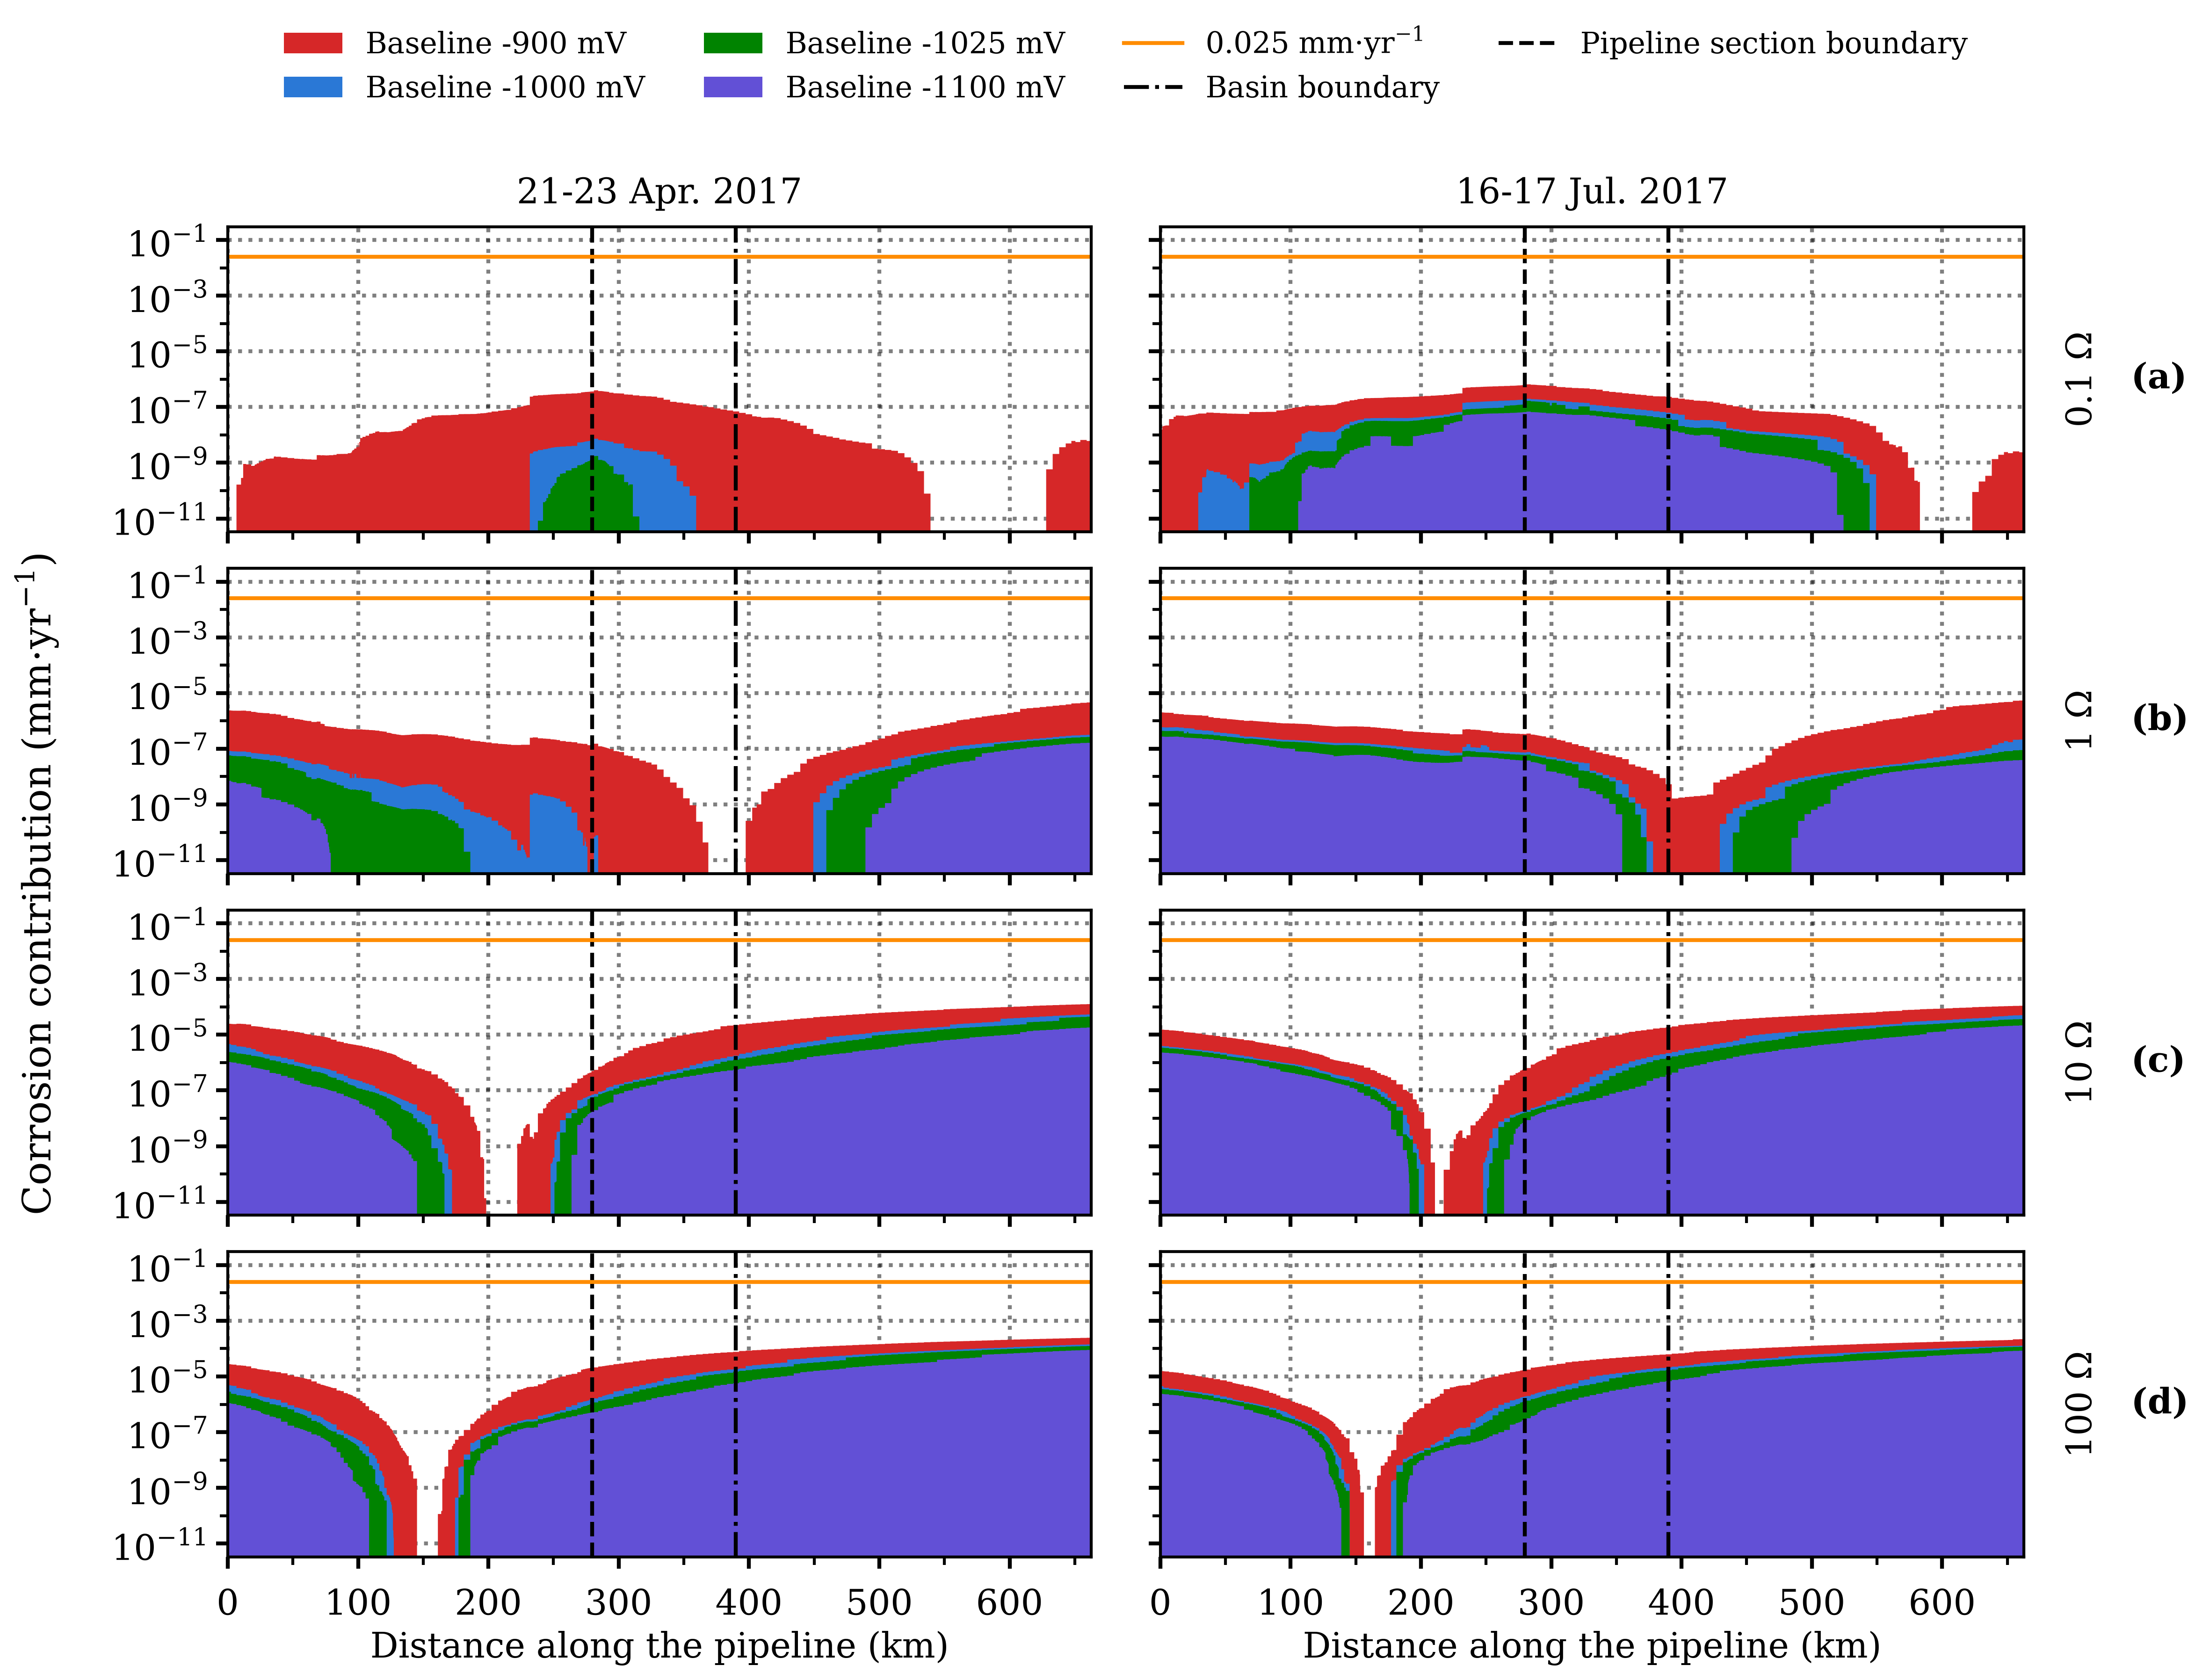

In [11]:
# Figure S3: corrosion contribution along the pipeline for each baseline
baseline_colors = {-0.900: "#d62728", -1.000: "#2a78d6", -1.025: "#008300", -1.100: "#6250d6"}
cr_bottom = 1e-11 / 3.0
cr_top = 1e-1 * 3.0
letters = ["a", "b", "c", "d"]

fig, axes = plt.subplots(nrows=len(zt_values), ncols=len(events), figsize=(16, 12), sharex="col", squeeze=False, dpi=300)

for col in range(len(events)):
    event = events[col]
    for row in range(len(zt_values)):
        zt = zt_values[row]
        ax = axes[row, col]

        # one bar layer per baseline, from the highest corrosion (-900 mV) to the lowest (-1100 mV)
        for k in range(len(baselines_V)):
            base = baselines_V[k]
            # nodes without corrosion are drawn at the bottom of the axis
            cr = cr_baseline[(event["id"], zt, base)].copy()
            for node in range(len(cr)):
                if not cr[node] > 0:
                    cr[node] = cr_bottom
            ax.fill_between(distance_km, cr_bottom, cr, step="mid", color=baseline_colors[base], linewidth=0, zorder=4 + k * 0.1)

        ax.set_yscale("log")
        ax.set_ylim(cr_bottom, cr_top)
        ax.set_yticks([1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-1])
        ax.set_yticks([1e-10, 1e-8, 1e-6, 1e-4, 1e-2], minor=True)
        ax.yaxis.set_minor_formatter(plt.NullFormatter())
        ax.grid(True, axis="both", color="black", alpha=0.5, linestyle=":", linewidth=2, zorder=1)
        ax.axvline(basin_line_km, color="black", linestyle="-.", linewidth=2.0, zorder=6)
        ax.axvline(pipeline_line_km, color="black", linestyle="--", linewidth=2.0, zorder=6)
        ax.axhline(0.025, color="darkorange", linestyle="-", linewidth=2.0, zorder=6)
        ax.set_xlim(distance_km[0], distance_km[-1])
        ax.xaxis.set_minor_locator(AutoMinorLocator(2))
        ax.tick_params(axis="y", which="major", labelsize=18, direction="out", length=6, width=2.0, labelleft=(col == 0))
        ax.tick_params(axis="y", which="minor", direction="out", length=4, width=1.5)
        ax.tick_params(axis="x", which="major", labelsize=18, direction="out", length=6, width=2.0, pad=10, labelbottom=(row == len(zt_values) - 1))
        ax.tick_params(axis="x", which="minor", direction="out", length=4, width=1.5)
        for spine in ax.spines.values():
            spine.set_linewidth(1.5)
            spine.set_zorder(10)

        if row == 0:
            ax.set_title(event["name"], fontsize=18, fontdict=font_props, pad=12)
        if col == len(events) - 1:
            ax.annotate(str(zt) + " $\\Omega$", xy=(1, 0.5), xycoords="axes fraction", xytext=(30, 0), textcoords="offset points",
                        fontsize=18, va="center", ha="center", rotation="vertical")
            ax.annotate("$\\mathbf{(" + letters[row] + ")}$", xy=(1, 0.5), xycoords="axes fraction", xytext=(55, 0), textcoords="offset points",
                        fontsize=18, va="center", ha="left")
    axes[-1, col].set_xlabel("Distance along the pipeline (km)", fontsize=18, fontdict=font_props)

fig.text(0.015, 0.47, "Corrosion contribution (mm$\\cdot$yr$^{-1}$)", fontsize=20, fontdict=font_props, va="center", ha="center", rotation="vertical")

legend_elements = []
for base in baselines_V:
    legend_elements.append(Patch(facecolor=baseline_colors[base], label="Baseline " + str(round(base * 1000)) + " mV"))
legend_elements.append(Line2D([0], [0], color="darkorange", linewidth=2.0, label="0.025 mm$\\cdot$yr$^{-1}$"))
legend_elements.append(Line2D([0], [0], color="black", linestyle="-.", linewidth=2.0, label="Basin boundary"))
legend_elements.append(Line2D([0], [0], color="black", linestyle="--", linewidth=2.0, label="Pipeline section boundary"))
fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=4, frameon=False, prop={"family": "serif", "size": 15})
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.07, top=0.86, wspace=0.08, hspace=0.12)

fig.savefig(figures_folder + "/FigS3_baseline_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()

# **Text S6: Sensitivity to the coating conductance (Tables S11 and S12)**

The calculations are repeated with the same coating conductance in both sections: 10⁻⁶ S·m⁻² (scenario A, the GARSOL value) and 10⁻⁸ S·m⁻² (scenario B, the GASCOM value). The shunt admittance per km is proportional to the coating conductance, so the main-text values are only rescaled. Table S11 gives the characteristic impedance Z0 and the propagation constant γ of each section, and Table S12 the maximum corrosion contribution in each section.

In [12]:
scenarios = [
    {"name": "Main text", "garsol": 1e-6, "gascom": 1e-8},
    {"name": "A", "garsol": 1e-6, "gascom": 1e-6},
    {"name": "B", "garsol": 1e-8, "gascom": 1e-8},
]

# field parallel to each segment, saved by the main notebook, inside the exposure window
e_parallel_by_event = {}
for event in events:
    df_parallel = pd.read_csv(output_folder + "/parallel_field_event_" + str(event["id"]) + ".csv")
    times = pd.to_datetime(df_parallel.columns[1:])
    in_window = (times >= event["exposure_start"]) & (times <= event["exposure_end"])
    e_parallel_by_event[event["id"]] = df_parallel.iloc[:, 1:].values[:, in_window]

rows_s11 = []
rows_s12 = []
for event in events:
    for zt in zt_values:
        rows_s12.append({"Period": event["period"], "Zt (ohm)": zt})

for scenario in scenarios:
    # shunt admittance per km of each segment, rescaled from the main-text value
    Y_new = np.zeros(n_segments)
    Ysh_new = np.zeros(n_segments)
    for i in range(n_segments):
        if i in garsol_nodes:
            Y_new[i] = Y_all[i] * scenario["garsol"] / coating_conductance_garsol
        else:
            Y_new[i] = Y_all[i] * scenario["gascom"] / coating_conductance_gascom
        Ysh_new[i] = Y_new[i] * segment_km_all[i] / 2

    # Z0 and gamma of each section (first and last segment)
    z0_garsol = np.sqrt(Z_all[0] / Y_new[0])
    z0_gascom = np.sqrt(Z_all[-1] / Y_new[-1])
    gamma_garsol = np.sqrt(Z_all[0] * Y_new[0])
    gamma_gascom = np.sqrt(Z_all[-1] * Y_new[-1])

    # table text: coating as 1e-06, Z0 with 2 decimals, gamma in scientific notation
    coating_text = "{:.0e}".format(scenario["garsol"]) + " / " + "{:.0e}".format(scenario["gascom"])
    z0_text = "{:.2f}".format(z0_garsol) + " / " + "{:.2f}".format(z0_gascom)
    gamma_text = sci(gamma_garsol) + " / " + sci(gamma_gascom)

    rows_s11.append({
        "Scenario": scenario["name"],
        "Coating conductance GARSOL / GASCOM (S/m2)": coating_text,
        "Z0 GARSOL / GASCOM (ohm)": z0_text,
        "gamma GARSOL / GASCOM (1/km)": gamma_text,
    })

    # maximum corrosion contribution in each section
    k = 0
    for event in events:
        for zt in zt_values:
            psp = solve_psp(e_parallel_by_event[event["id"]], Ye_all, Ysh_new, Z_all, zt, base_psp_V)
            cr, exposure = corrosion_per_node(psp)
            max_cr_garsol = cr[garsol_nodes].max()
            max_cr_gascom = cr[gascom_nodes].max()
            rows_s12[k][scenario["name"] + " GARSOL"] = sci(max_cr_garsol)
            rows_s12[k][scenario["name"] + " GASCOM"] = sci(max_cr_gascom)
            k = k + 1

tables = {
    "S11": pd.DataFrame(rows_s11),
    "S12": pd.DataFrame(rows_s12),
}

for name in tables:
    tables[name].to_csv(tables_folder + "/Table_" + name + ".csv", index=False)
    print("Table " + name)
    print(tables[name].to_string(index=False))
    print()

Table S11
 Scenario Coating conductance GARSOL / GASCOM (S/m2) Z0 GARSOL / GASCOM (ohm) gamma GARSOL / GASCOM (1/km)
Main text                              1e-06 / 1e-08             3.40 / 29.37          4.89e-03 / 4.69e-04
        A                              1e-06 / 1e-06              3.40 / 2.94          4.89e-03 / 4.69e-03
        B                              1e-08 / 1e-08            34.02 / 29.37          4.89e-04 / 4.69e-04

Table S12
Period  Zt (ohm) Main text GARSOL Main text GASCOM A GARSOL A GASCOM B GARSOL B GASCOM
 April       0.1         1.36e-09         1.79e-09        -        - 1.89e-08 2.13e-08
 April       1.0         6.00e-08         2.70e-07 6.11e-08 2.19e-07 1.13e-07 2.45e-07
 April      10.0         2.53e-06         4.56e-05 6.20e-06 5.79e-06 1.79e-05 1.95e-05
 April     100.0         2.97e-06         1.27e-04 1.21e-05 1.25e-05 4.70e-05 6.10e-05
  July       0.1         1.27e-07         1.70e-07 5.90e-08 6.63e-08 2.90e-07 3.02e-07
  July       1.0         4.52